# On the 67M, what tells a fine-tune that builds on the model from one that adds something new?

**The answer.** On the 67M model, where we explore before testing on Qwen, the re-gating share reads higher on the side built to reuse in every built task pair where it was read. That separation vanishes when the trained decomposition is swapped for an untrained one. But the share mostly follows how likely the original model already found the answer. It also cannot tell a real fine-tune from its shuffled-label twin, where steering and the update's spectrum can, probably for plainer reasons.

*Everything here is provisional. The definition of reused against new is under revision. Every pair keeps the labels it was built with, and nothing in this notebook says whether any fine-tune reused or added anything. The 67M is the exploration set; Qwen3-1.7B is the later test set. The notebook reads saved results only and loads no model.*


## What is being compared

**Task pairs.** A task pair is two fine-tunes of the 67M on matching windows. One side is built to reuse something the model already does, such as copying a token that already sits in the window. The other side is built to be new, such as a random map or a cipher from keys to answers. Most pairs carry their labels by assumption only. One pair, copy at a new marker against lookup, was labelled by a causal check, and its copy side is not settled as filed.

**Shuffled-label twins.** A twin is fine-tuned on the same words with the link between word and label shuffled, so it can only memorise. It is the contrast the tentative definition leans on.

**The gain.** At the trigger position of held-out windows, let $T_1$ be the log-odds of the trained answer under the fine-tuned model and $T_0$ the same under the original model. The gain is $T_1 - T_0$. Each method below is a share of that gain: 0 means the method recovers none of it, 1 means all of it.

**The methods.**

- **The re-gating share**, called *the share* from here on. Keep the decomposition's original subcomponents, leave Δ out, and change only the causal importances Γ assigns. Let $M_0$ be the masked log-odds with Γ's values on the original model's activations and $M_1$ the same with Γ's values on the fine-tuned model's. The share is $(M_1 - M_0)/(T_1 - T_0)$. It can exceed 1.
- **The neuron version** does the same with MLP neurons and no decomposition: the original model's output weights are fed the fine-tuned model's neuron firing.
- **Steering** adds one mean shift to the original model's residual stream, either one vector for all windows, called pooled, or one vector per key or per word.
- Two readings that are not shares: **the prior**, the original model's probability of the trained answer before any fine-tune, and **the update's spectrum**, the effective rank of the weight change.

Each section below says the rule it used to call two sides apart. The rules differ between runs, and each was filed before its run.


In [1]:
import json
from pathlib import Path

from IPython.display import Image, display

EXP = Path("../experiments")


def load(path):
    return json.loads((EXP / path).read_text())


## 1. Where part 2 started: which methods sort the built pairs?

The scorecard gathered every saved reading of each method on the 67M task pairs into one table, before part 2's new runs. It filed no rule. The cell below uses the simplest one: a method sorts a pair when every seed on the side built to reuse reads above every seed on the side built to be new. The figure is the scorecard itself: filled dots are the side built to reuse, hollow dots the side built to be new.


the share              reuse side above on 9 of 9 pairs read, below on 0
steering               reuse side above on 7 of 8 pairs read, below on 0
neurons, whole firing  reuse side above on 3 of 7 pairs read, below on 3
neurons, input only    reuse side above on 3 of 7 pairs read, below on 1


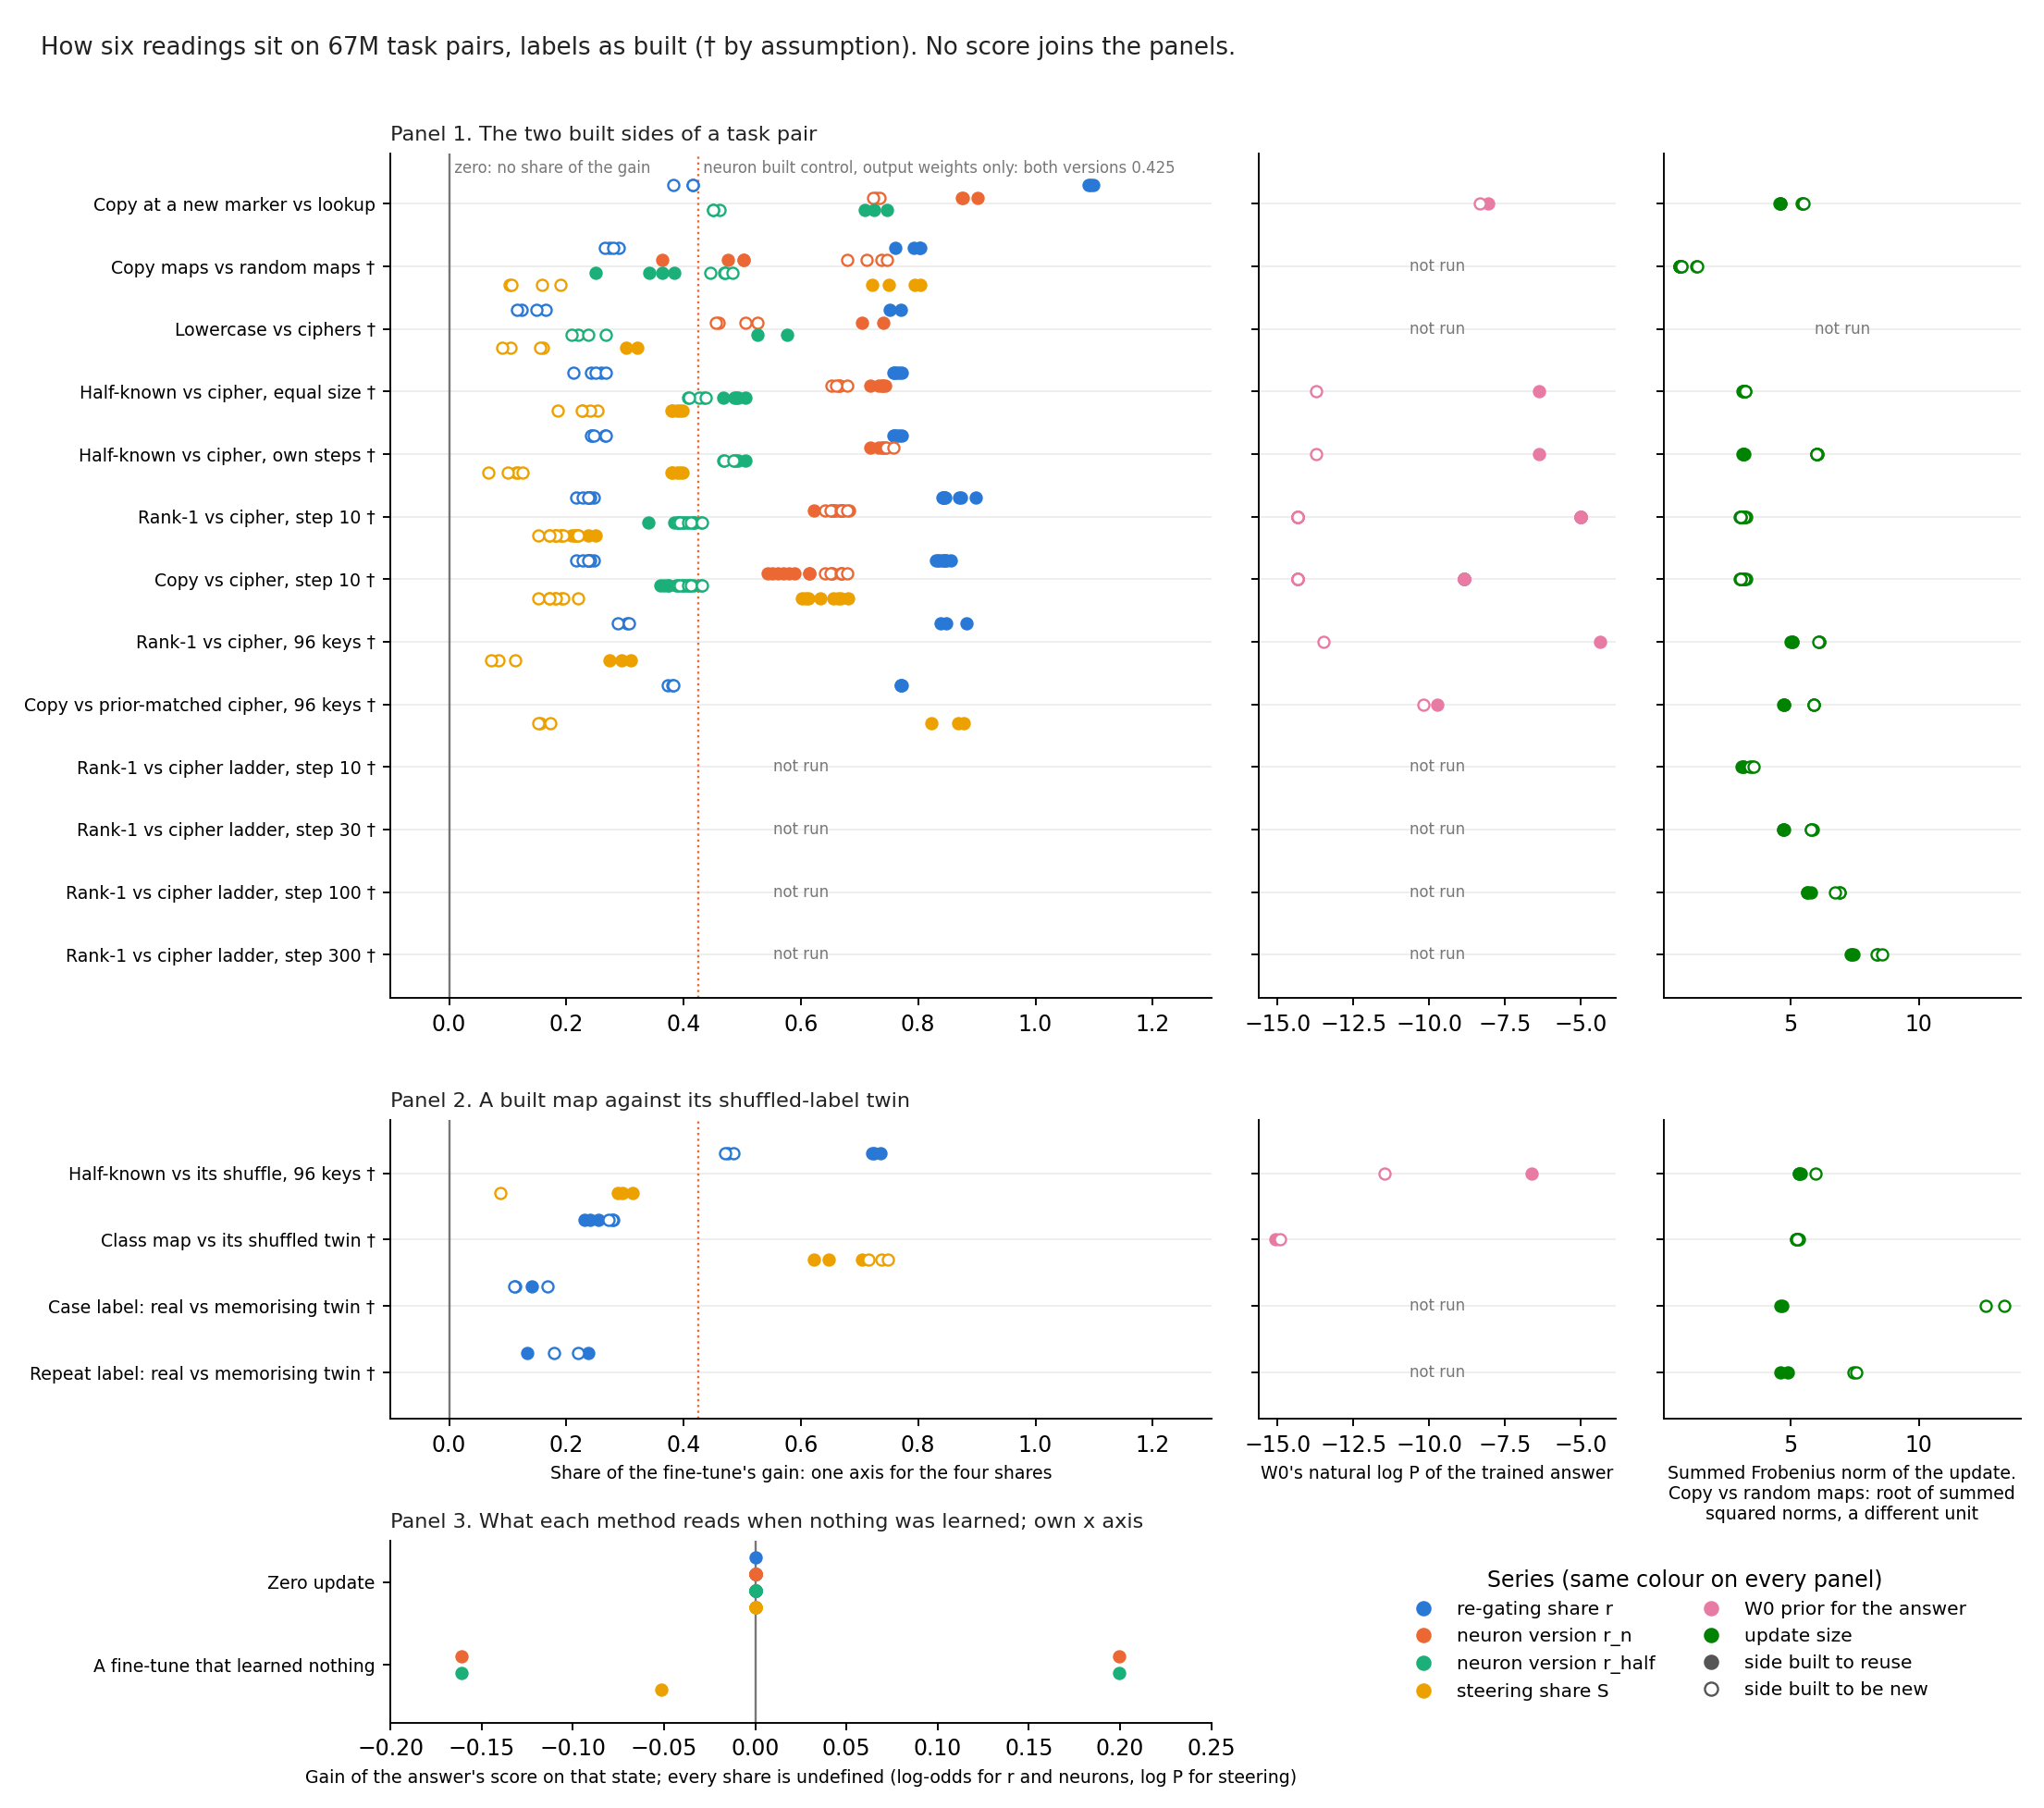

In [2]:
card = load("method_table/results/scorecard.json")
names = {"r": "the share", "S": "steering", "r_n": "neurons, whole firing", "r_half": "neurons, input only"}
for m, name in names.items():
    rows = [c["value"] for c in card if c["method"] == m and c["criterion"] == "built_pair_sides"
            and isinstance(c["value"], dict) and isinstance(c["value"].get("reuse"), list)]
    above = sum(min(v["reuse"]) > max(v["new"]) for v in rows)
    below = sum(max(v["reuse"]) < min(v["new"]) for v in rows)
    print(f"{name:22s} reuse side above on {above} of {len(rows)} pairs read, below on {below}")
display(Image(EXP / "method_table/figures/scorecard.png", width=1000))


**Reading it.** The share sorted every built pair it was read on: the side built to reuse read higher on all nine, with no seed overlap. Steering sorted seven of the eight it was read on by this simple rule. The method table's own rule, in log-odds and with a null check, counted steering on 5 of 10, so steering's count depends on the rule and unit. The neuron version sorted only three of seven, and on copy maps against random maps it read the other way round.

**Its limit.** The prior panel shows the problem the next section takes up. The prior is far higher on the side built to reuse on every pair except the two built to match it. So a method that sorts these pairs may be reading the prior and not what the fine-tune did.


## 2. Does the share just follow the original model's prior?

**What was asked.** Over every saved map, does the original model's prior order the maps as the share does? One forward pass of the original model filled the prior wherever it had not been saved, for 24 maps. The prior here is the geometric mean, over windows, of the original model's probability of the trained answer. The test is the rank correlation between the share and the log prior. A shuffled pairing of shares and priors gives the null: its 95th percentile is the bar a real agreement must clear.


rank correlation, share against log prior over 24 maps: 0.85
95% bootstrap interval 0.67 to 0.93; shuffled-pairing null, 95th percentile 0.35
  copy                   prior 3.9e-05   share 0.78
  copy                   prior 5.9e-05   share 0.77
  prior-matched cipher   prior 3.7e-05   share 0.38
  copy                   prior 3.2e-04   share 1.09
  lookup                 prior 2.4e-04   share 0.40


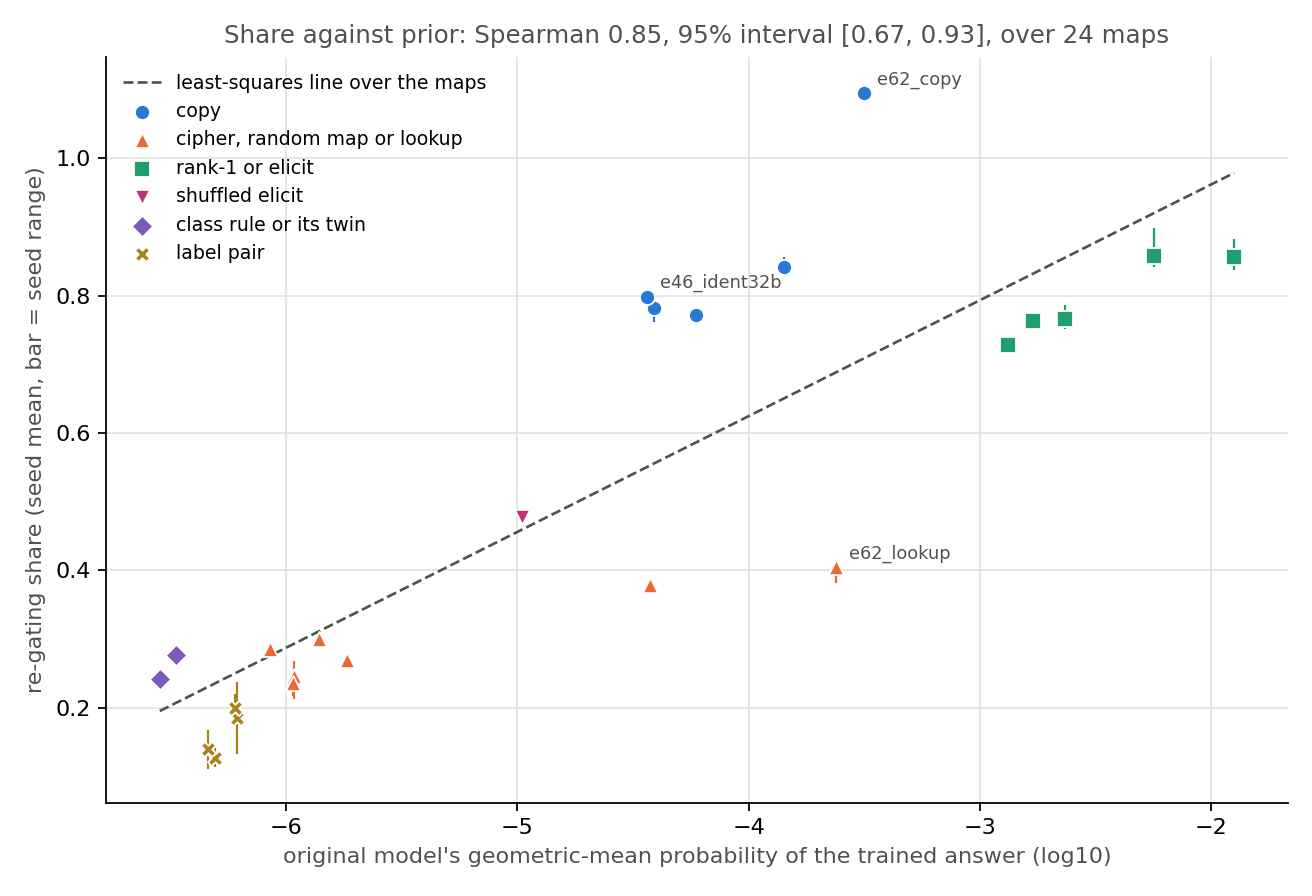

In [3]:
pv = load("prior_vs_share/results/stage2.json")
print(f"rank correlation, share against log prior over {pv['n_maps']} maps: {pv['spearman']:.2f}")
print(f"95% bootstrap interval {pv['ci95'][0]:.2f} to {pv['ci95'][1]:.2f}; shuffled-pairing null, 95th percentile {pv['null95']:.2f}")
pts = {p["name"]: p for p in pv["points"]}
for n in ("e46_ident32", "e58_96_copy", "e58_96_prior_cipher", "e62_copy", "e62_lookup"):
    p = pts[n]
    print(f"  {p['built']:22s} prior {p['prior']:.1e}   share {p['share']:.2f}")
display(Image(EXP / "prior_vs_share/figures/share_vs_prior.png", width=900))


**Reading it.** Mostly yes: the share's rank follows the prior closely. Over 24 maps the correlation is 0.85. Shuffled pairings reach only 0.35. Where the share departs from the prior is where it might carry something extra. At almost the same prior, copy maps read 0.77 to 0.80 and the prior-matched cipher reads 0.38. The new-marker copy sits high, at 1.09, and its lookup partner low, at 0.40.

**Its limits.** One table enters more than once at several key counts, so the interval is too narrow. Part of the link may be built in, because the gain starts from $T_0$, the original model's log-odds of the same answer the prior describes. The copy maps that sit off the line all have their answer in the window, so the departures are one kind of task. The premise check on this question came back doubtful: if the share mostly reads the starting point, it may say little about what was learned.


## 3. Does steering separate copy from lookup as widely as the share?

**What was asked.** This is the one pair with a causal-check label: copy at a new marker against a lookup with no link to the window, three fine-tune seeds per side, 100 scored windows. Steering got its fair form here: a pooled vector, and one vector per key, each with its strength tuned on separate windows. The rule filed before the run compares the share's copy-minus-lookup gap with the wider of steering's two gaps. The smallest edge that counts is 0.1.


copy minus lookup: share 0.69, pooled steering 0.41, per-key steering -0.02
the share's edge over the wider steering gap: 0.27


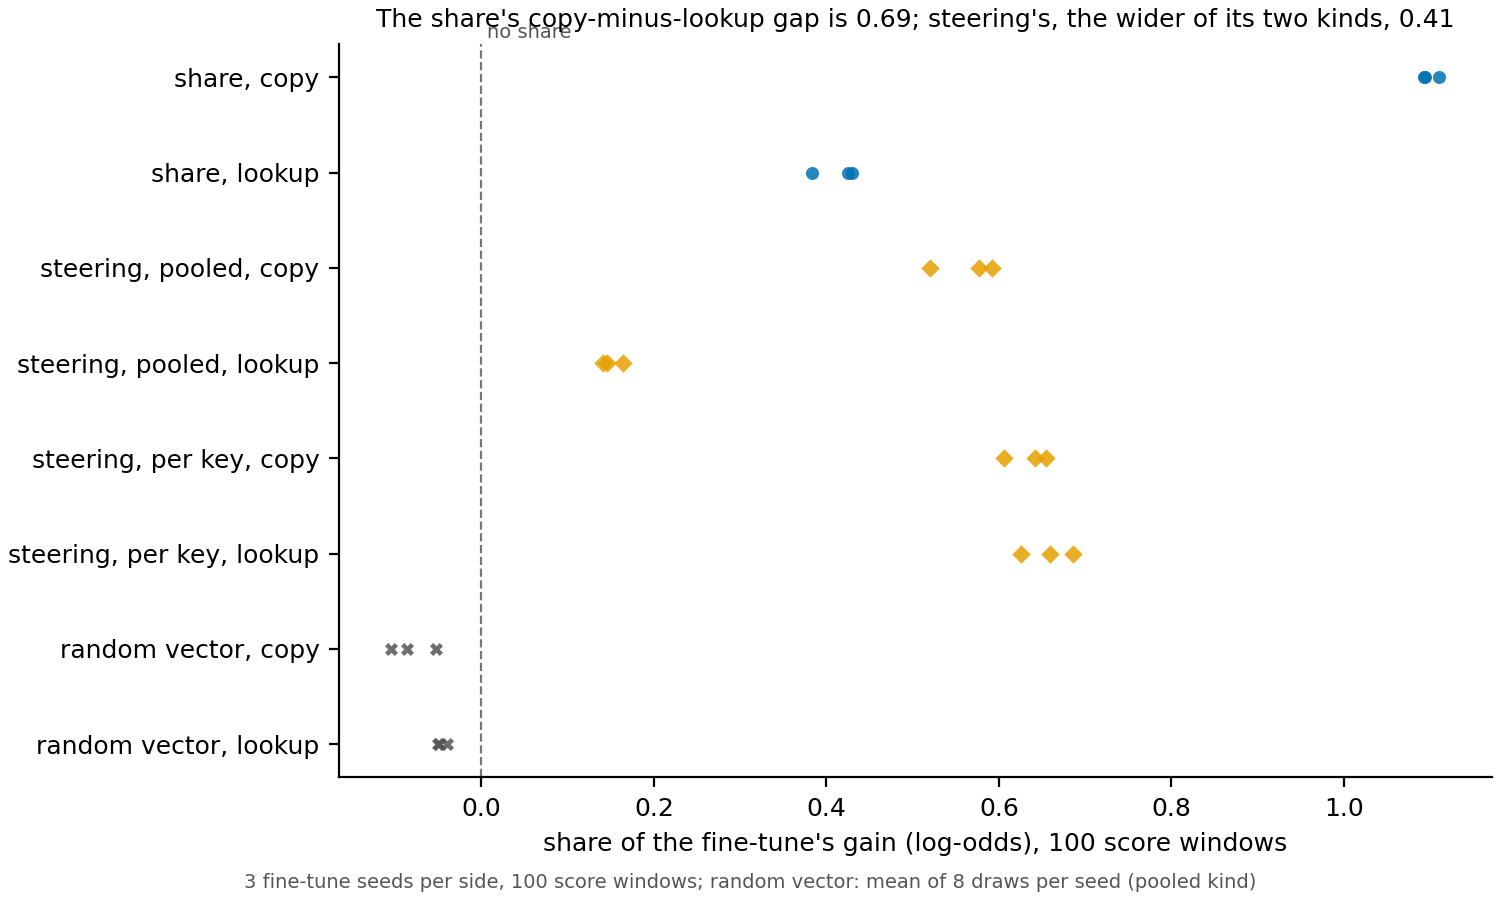

In [4]:
sc = load("steering_copy_lookup/results/stage1.json")["score"]
print(f"copy minus lookup: share {sc['gap_share']:.2f}, pooled steering {sc['gap_pooled']:.2f}, per-key steering {sc['gap_perkey']:.2f}")
print(f"the share's edge over the wider steering gap: {sc['edge']:.2f}")
display(Image(EXP / "steering_copy_lookup/figures/steering_copy_lookup.png", width=900))


**Reading it.** The share's gap stayed the wider one, so under the filed rule the share keeps an edge on this pair. Its gap is 0.69 of the gain; pooled steering's is 0.41, an edge of 0.27. But the edge holds over pooled steering only. One vector per key raises lookup to 0.63 to 0.69. Copy stays at 0.61 to 0.65, so that gap all but vanishes. What steering says about this pair depends on the kind of vector. A likely reason, untested, is that one vector cannot hold 32 different answers while one per key can.

**Its limits.** Random vectors of the same size read below zero, as they should. The per-key random vector on lookup read 0.12 below zero, outside its band of 0.1, so that reading carries a mark. The strength was chosen on windows the per-key vectors were fitted on, which favours per-key steering. The premise check came back doubtful: the pooled gap may record whether one direction serves every key, a fact about the task's structure, and the share could be tracking the same thing.


## 4. Does the separation need a trained decomposition?

**What was asked.** If any split of the weights into pieces gave the same gaps, the share would owe nothing to the trained decomposition. So the trained decomposition was replaced by two that need no training: each matrix's singular value decomposition, and the same with its directions randomly rotated. Neither has a trained Γ, so a fixed rule picks the pieces. At each position it keeps those with the largest contribution, as many as the trained decomposition switches on, between 1 and 30 per matrix. The saved fine-tunes were read on all three versions. Five pairs could be scored; the twin pairs are described only.


gap, side built to reuse minus side built to be new:
  copy against random table                trained 0.51  SVD -0.03  rotated -0.04
  elicit against cipher, sizes matched     trained 0.52  SVD +0.07  rotated +0.09
  rank-1 against cipher, 24 trained keys   trained 0.62  SVD -0.05  rotated -0.10
  copy against cipher, 24 trained keys     trained 0.61  SVD +0.05  rotated -0.12
  copy at a new marker against lookup      trained 0.69  SVD +0.06  rotated +0.16
mean share over all 68 saved updates: trained 0.50, SVD 0.07


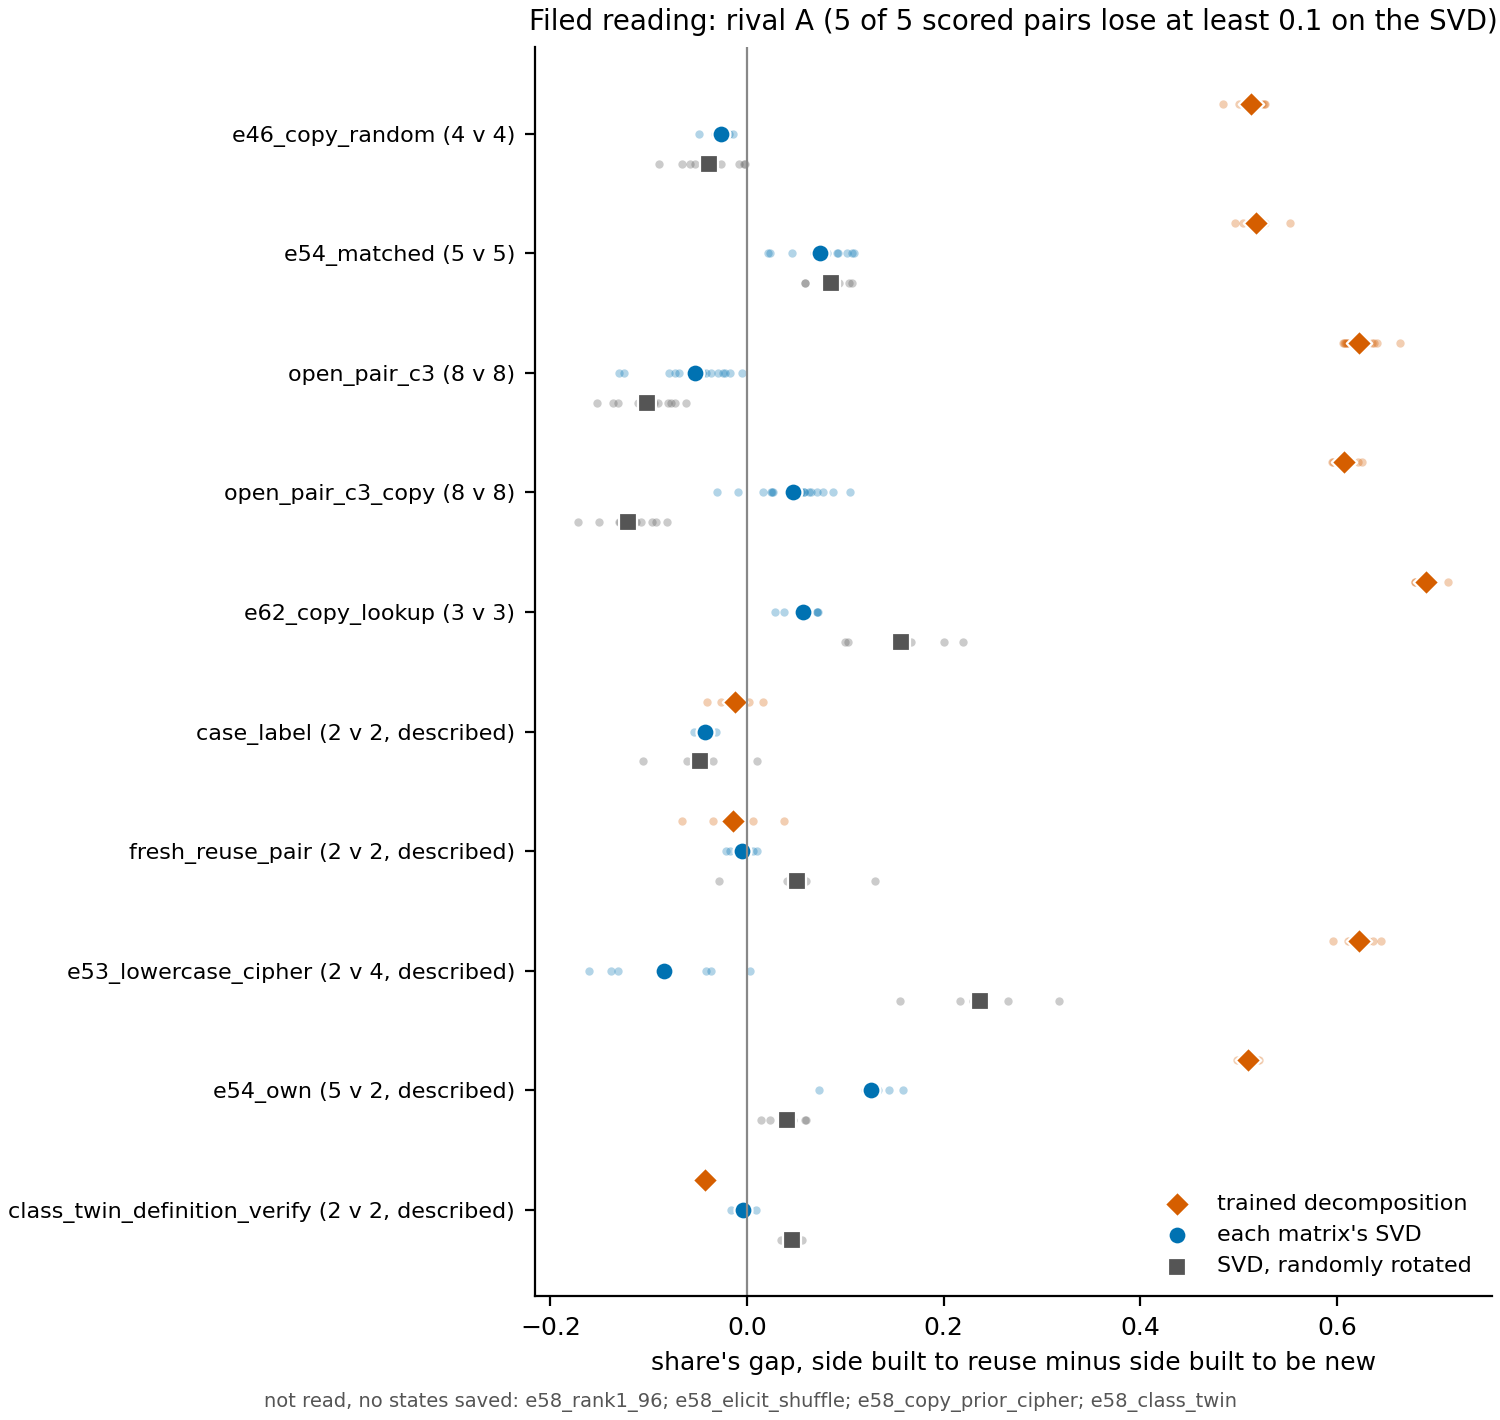

In [5]:
un = load("share_untrained/results/stage1.json")
print("gap, side built to reuse minus side built to be new:")
for p in un["pairs"]:
    if p["scored"]:
        print(f"  {p['built'][:40]:40s} trained {p['trained']['gap']:.2f}  SVD {p['svd']['gap']:+.2f}  rotated {p['rotated']['gap']:+.2f}")
st = list(un["states"].values())
print(f"mean share over all {len(st)} saved updates: trained {sum(s['trained'] for s in st) / len(st):.2f}, SVD {sum(s['svd'] for s in st) / len(st):.2f}")
display(Image(EXP / "share_untrained/figures/gaps.png", width=850))


**Reading it.** Yes, under this rule for picking pieces: on all five scored pairs the gap disappears without training. The trained gaps run from 0.51 to 0.69 of the gain. On the singular value decomposition they run from 0.05 below zero to 0.07 above, and the rotated version reads little too. The share itself is low everywhere without training, averaging 0.07 against 0.50 on the trained decomposition, so the untrained reading is not only flat between the sides.

**Its limits.** The swap changes the pieces, the rule that picks them and how well the model is reproduced, all at once. With the fixed rule the untrained versions reproduce the original model worse. Its masked answer log-odds sit 3.1 below the original on average on the singular value decomposition, and 24.1 below on the rotated one. The trained decomposition sits 0.8 above. So a low share here could mean the pieces lack what the share needs, or that this rule picks poorly; the run cannot tell. The premise check came back doubtful for this reason. Even a clean result would fit a share that mainly reads the starting point, since Γ is trained on the original model.


## 5. Can any method tell a real fine-tune from its shuffled-label twin?

**What was asked.** Two pairs, three seeds per side. After a marker token the model must say one of two label words. The real fine-tune learns a rule about the word before the marker: whether it is capitalised on the case-label pair, whether it already occurred in the window on the repeat-label pair. Its twin sees the same words with labels shuffled per word. Each method is read in the label contrast, the logit of one label minus the other, signed toward the window's own label, on 256 rows. A method calls the arms apart when the gap is at least 0.1 and at least twice its standard error over seeds. A method whose shares are all under 0.05 in size writes almost nothing and makes no call.


real minus twin, as a share of each fine-tune's own gain:
  the share             case -0.02 not apart  repeat -0.09 not apart
  steering, per word    case -0.51 apart      repeat -1.09 apart    
  steering, pooled      case +0.10 apart      repeat -0.01 inert    
  neurons, top 64       case -0.01 inert      repeat +0.01 inert    


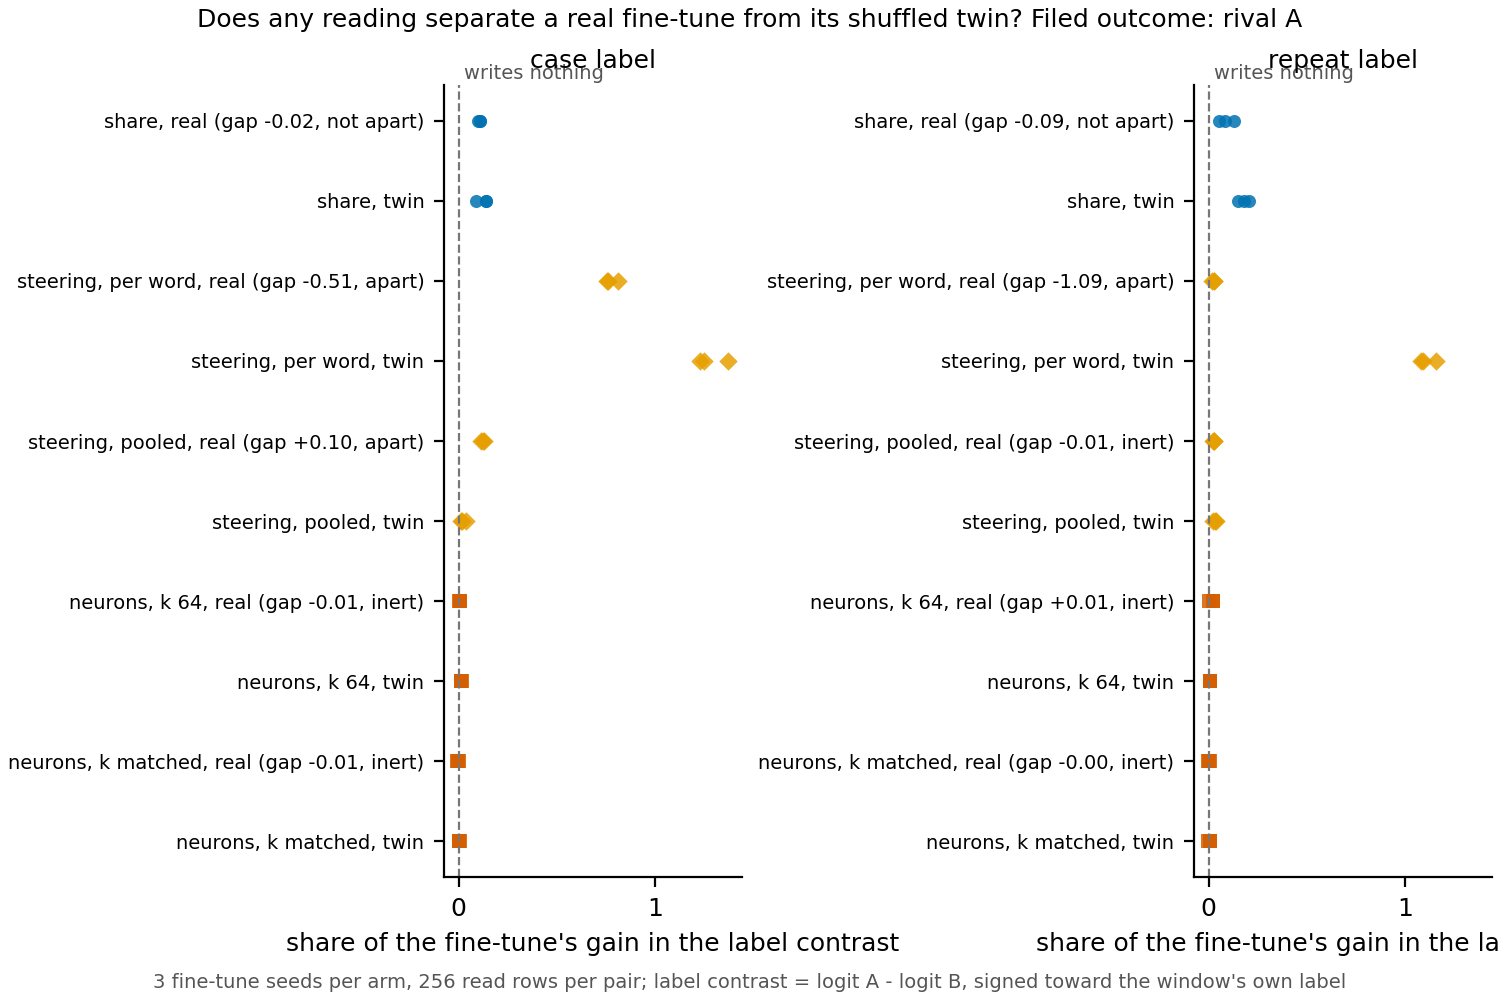

In [6]:
rt = load("real_vs_twin/results/stage3.json")["score"]["contrast"]
names = {"share": "the share", "steer_perword": "steering, per word", "steer_pooled": "steering, pooled", "neuron_k64": "neurons, top 64"}
print("real minus twin, as a share of each fine-tune's own gain:")
for m, name in names.items():
    print(f"  {name:20s}" + "".join(f"  {pair} {rt[m][pair]['gap']:+.2f} {rt[m][pair]['call']:9s}" for pair in ("case", "repeat")))
display(Image(EXP / "real_vs_twin/figures/shares.png", width=1000))


**Reading it.** The share does not tell real from twin; steering does; the neuron version writes almost nothing. The share's gaps are 0.02 and 0.09, both under the bar, with the twin above. Per-word steering reads 0.776 of the gain on the real case fine-tune against 1.282 on its twin. On the repeat pair it reads 0.023 against 1.109. Pooled steering clears the bar on the case pair by a hair, at 0.101.

**Why that may not mean much.** The steering gaps have plain causes. A twin's label is a fixed function of the word, so a per-word vector fitted on that word's windows carries the answer itself. On the case pair the twin also trained longer and wrote a larger update: it ran to step 300 against 30, with a summed norm of about 13 against 4.6. On the repeat pair the update sizes are close, so this cause applies to the case pair only. Every twin's per-word share is above 1, so the vector overshoots the twin's own gain. The premise check came back doubtful: the next section shows that the update's shape alone also separates these pairs, so passing this test does not show a method sees what was learned.


## 6. Does the update's spectrum alone do what the share does?

**What was asked.** The cheapest possible rival needs no model at all: look only at the weight change. Its effective rank counts how many directions the change spreads over, from its singular values alone: ten equal directions read 10, one reads 1. For nine pairs, a pair counts as separated when the gap between its two sides is larger than the wider spread inside one side. The share was scored by the same rule on the same fine-tunes.


pairs separated: effective rank 5 of 9, share 7 of 9, both 3
separated by the rank only: e123_case_label, e125_repeat_label
a fine-tune that learned nothing: effective rank 562


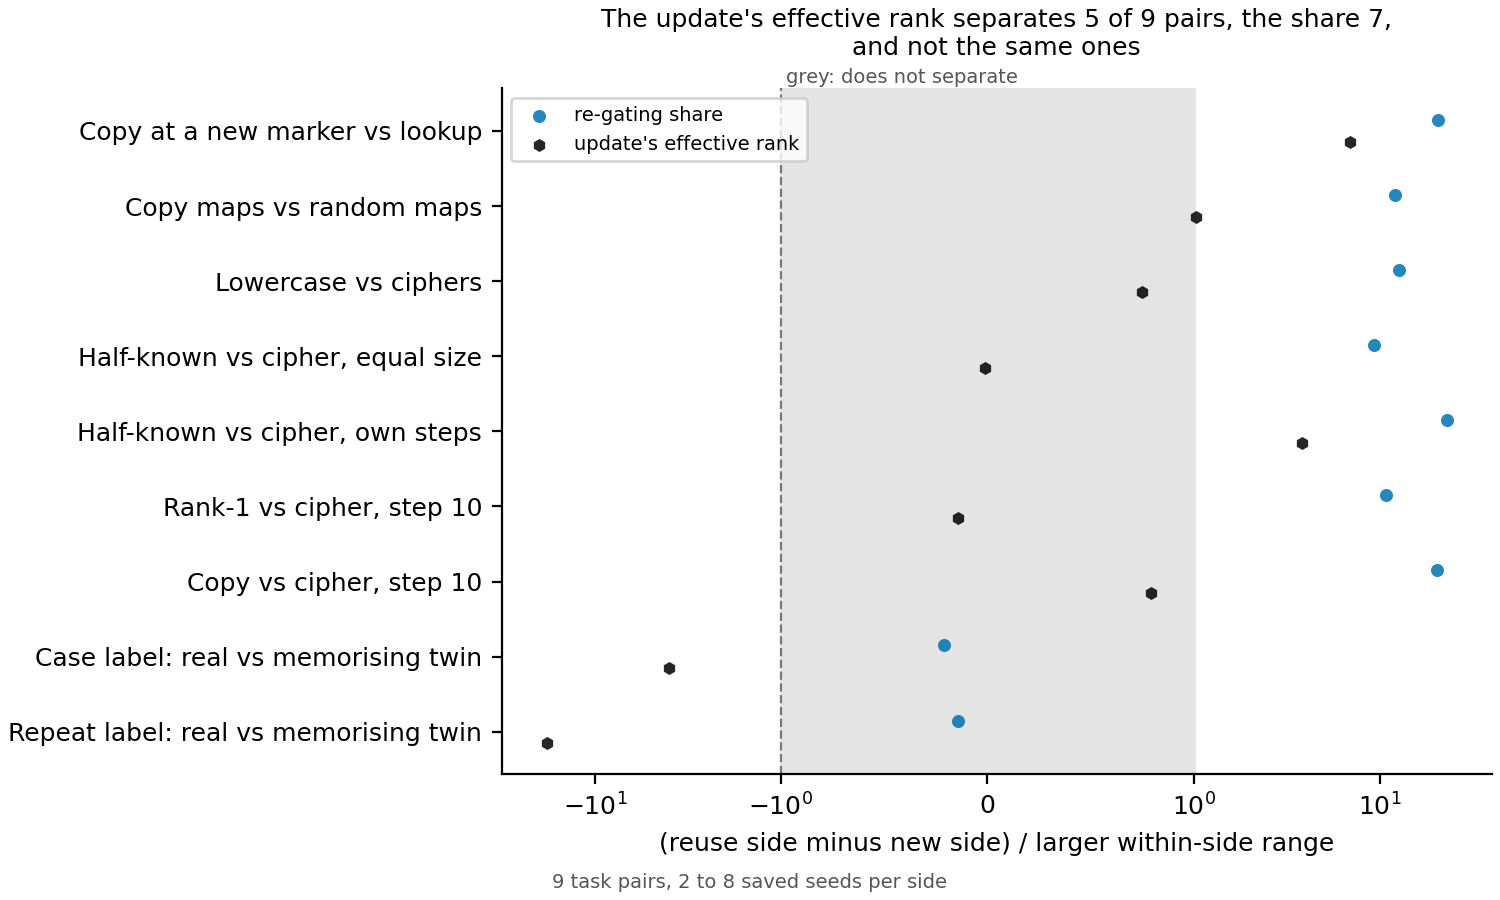

In [7]:
sv = load("update_svd/results/results.json")
sep = sv["score"]["separating"]
n = len(sv["pairs"])
print(f"pairs separated: effective rank {len(sep['erank'])} of {n}, share {len(sep['r'])} of {n}, both {len(set(sep['erank']) & set(sep['r']))}")
print("separated by the rank only:", ", ".join(sv["score"]["P2"]["erank_only"]))
print(f"a fine-tune that learned nothing: effective rank {sv['learned_nothing']['erank']:.0f}")
display(Image(EXP / "update_svd/figures/gaps.png", width=900))


**Reading it.** No: the spectrum is no substitute for the share on these pairs, and the two read different things. The rank separates five pairs and the share seven, and they agree on only three. The rank misses both pairs whose sides have about the same update size: its gaps there are 0.07 and 1.6, against spreads of 6.7 and 11.4. It separates both label pairs the share does not, with the side built to reuse lower. On those pairs the twin trained three to ten times longer, so the rank looks more like a record of training length, a cause this run does not test. A fine-tune that learned nothing reads 562, above every pair, so a high rank marks a spread-out change and not learning.

**What this adds.** It makes the previous section harder to read in steering's favour. If the update's shape alone tells real from twin, a method that passes that test may only be seeing the longer training.


## 7. PLACEHOLDER: filling the neuron and steering holes

**Results pending; another pass fills this section.** The run reads steering in its fair form, pooled and per-key vectors with strength tuned, on six saved pairs, and the top-k neuron version on seven. It reads them on the same rows the share was read on, so the scorecard's empty steering and neuron cells get numbers. Its results will land in `experiments/holes_fill/results/`. Until then this section has no figure and no reading, and nothing above depends on it.


## Where the share helps and where it does not, so far

All of this is provisional, read on the 67M with labels as built, and no row says whether any fine-tune reused anything.

**Where it helps.**

- It sorts the built pairs: it reads higher on the side built to reuse on all nine where it was read. That includes the pairs built to equal update size, which update size and the spectrum do not sort.
- It departs from the prior where a test needs it to: copy maps read about twice the prior-matched cipher at the same prior, and the new-marker copy reads far above its lookup.
- Its separation needs the trained decomposition: an untrained split, under one fixed rule for picking pieces, reads no gap.
- On the one causally labelled pair its gap beats pooled steering's by more than the bar.

**Where it does not.**

- Across maps it mostly follows the original model's prior, with a rank correlation of 0.85, and part of that link may be built into its denominator.
- It does not tell a real fine-tune from its shuffled-label twin. Steering and the spectrum do, but most likely through the per-word key and, on the case pair, the twin's larger update.
- Its edge over steering depends on the kind of vector: one vector per key closes the gap on copy against lookup.
- Every pair but one carries its labels by assumption, and that one pair's copy side is not settled as filed.

For the later test on Qwen, the readings that carried information here were those at matched prior or matched update size; most others could be explained by the prior or by training length.


## Not run

- Any verdict on reuse: the definition is under revision, so none is given under any wording.
- An independent check of any reading here; each is one run.
- A share gap at matched update size and matched prior on a task that is not a copy map.
- Steering and the neuron version on most pairs; the pending run in section 7 fills some of these.
- Steering at a strength matched between real and twin, per-word vectors fitted on windows the fine-tune never saw, and twins stopped at the real fine-tune's step or norm.
- The untrained decomposition with any other rule for picking pieces, continuous values in place of keep-or-drop, or more faithful masking.
- The effective rank against update size and training steps, as a test of the training-length reading.
- Four pairs whose fine-tunes were never saved: rank-1 against cipher at 96 keys, copy against the prior-matched cipher, half-known against its shuffle, and the class map against its twin. They have share readings but no untrained or spectrum reading.
- A second trained decomposition, so nothing here says how much of the share belongs to this Γ.
- Anything on Qwen3-1.7B.

## Departures from the literature

- Steering by a mean difference at one layer follows activation addition; the per-key and per-word vectors and the strength grid are additions made here.
- Replacing a trained decomposition with each matrix's singular value decomposition, and keeping the largest-contributing pieces, are this project's stand-ins, not a method from the parameter decomposition papers.
- The effective rank is Roy and Vetterli's, averaged over matrices by squared size.
- The share, the neuron version and the steering share are this project's own measures.

## Premise checks

Each run's premise check came back doubtful. The checks are advisory and are kept at `~/commute-data/premise/`: `P2.3.md` for the prior, `P2.5.md` for copy against lookup, `P2.8.md` for the untrained decomposition, `P2.4.md` for real against twin, `P2.9.md` for the spectrum. The shared doubt is that the built sides of each pair differ in more than how they were built. They also differ in prior, update size, training length and task structure, and a method that sorts them may be reading one of those.

## Provenance

| section | record | results |
|---|---|---|
| 1 | `reports/analyses/2026-11-09_analysis_scorecard.md`, `..._what-regating-does.md` | `experiments/method_table/results/scorecard.json` |
| 2 | E133, `experiments/TRIED.md`; job 56889 | `experiments/prior_vs_share/results/stage2.json` |
| 3 | E135, `reports/analyses/2026-11-09_analysis_e135-steering-copy-lookup.md`; job 56927 | `experiments/steering_copy_lookup/results/stage1.json` |
| 4 | E136, `reports/analyses/2026-11-09_analysis_e136-share-untrained.md` | `experiments/share_untrained/results/stage1.json` |
| 5 | E140, `reports/analyses/2026-11-10_analysis_e140-real-vs-twin.md`; jobs 57740, 57752 | `experiments/real_vs_twin/results/stage3.json` |
| 6 | E141, `reports/analyses/2026-11-10_analysis_e141-update-svd.md` | `experiments/update_svd/results/results.json` |
| 7 | E143, pending | `experiments/holes_fill/results/` |

All runs were on the free MATS queue or CPU, at $0. This notebook reads saved JSON and figures only.
